In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [2]:
df=pd.read_csv('Churn_Modelling.csv')


In [3]:
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15642986,Khan,678,Spain,Female,20,10,0.00,2,1,0,166866.80,0
1,2,15568909,Rossi,518,France,Female,35,2,87695.64,1,1,0,66333.03,0
2,3,15644226,Brown,589,Spain,Male,21,3,0.00,1,1,1,119693.37,0
3,4,15645882,Khan,747,Germany,Male,59,2,137433.90,1,1,1,69419.68,1
4,5,15629385,Brown,745,France,Male,41,3,40078.36,1,1,1,108106.13,0


In [13]:
df.dropna()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_France,Geography_Germany,Geography_Spain,Gender_Female,Gender_Male
0,678,20,10,0.00,2,1,0,166866.80,0,0,0,1,1,0
1,518,35,2,87695.64,1,1,0,66333.03,0,1,0,0,1,0
2,589,21,3,0.00,1,1,1,119693.37,0,0,0,1,0,1
3,747,59,2,137433.90,1,1,1,69419.68,1,0,1,0,0,1
4,745,41,3,40078.36,1,1,1,108106.13,0,1,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,709,52,5,122454.99,2,0,1,13820.75,0,1,0,0,1,0
9996,578,45,3,124976.62,1,1,1,135835.27,0,1,0,0,0,1
9997,500,56,8,0.00,2,1,0,93610.26,0,1,0,0,1,0
9998,558,44,6,87506.17,2,1,0,148796.94,0,1,0,0,1,0


In [14]:
df.drop_duplicates()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_France,Geography_Germany,Geography_Spain,Gender_Female,Gender_Male
0,678,20,10,0.00,2,1,0,166866.80,0,0,0,1,1,0
1,518,35,2,87695.64,1,1,0,66333.03,0,1,0,0,1,0
2,589,21,3,0.00,1,1,1,119693.37,0,0,0,1,0,1
3,747,59,2,137433.90,1,1,1,69419.68,1,0,1,0,0,1
4,745,41,3,40078.36,1,1,1,108106.13,0,1,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,709,52,5,122454.99,2,0,1,13820.75,0,1,0,0,1,0
9996,578,45,3,124976.62,1,1,1,135835.27,0,1,0,0,0,1
9997,500,56,8,0.00,2,1,0,93610.26,0,1,0,0,1,0
9998,558,44,6,87506.17,2,1,0,148796.94,0,1,0,0,1,0


In [6]:
df = df.drop(columns=["RowNumber", "CustomerId", "Surname"])

In [15]:
df.head()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_France,Geography_Germany,Geography_Spain,Gender_Female,Gender_Male
0,678,20,10,0.00,2,1,0,166866.80,0,0,0,1,1,0
1,518,35,2,87695.64,1,1,0,66333.03,0,1,0,0,1,0
2,589,21,3,0.00,1,1,1,119693.37,0,0,0,1,0,1
3,747,59,2,137433.90,1,1,1,69419.68,1,0,1,0,0,1
4,745,41,3,40078.36,1,1,1,108106.13,0,1,0,0,0,1


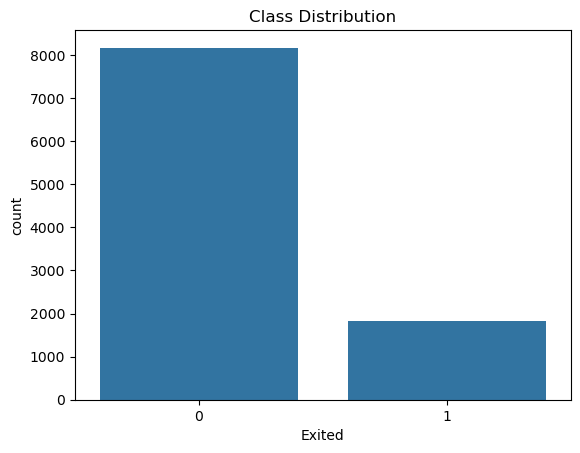

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(data=df, x="Exited")
plt.title("Class Distribution")
plt.show()

In [9]:
df = pd.get_dummies(df, columns=["Geography", "Gender"], dtype=int)

In [ ]:
X=df.drop(columns=['Exited'])
y=df['Exited']

In [16]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

ValueError: Found input variables with inconsistent numbers of samples: [9998, 10000]

In [63]:
df = pd.get_dummies(df, columns=["Geography", "Gender"], dtype=int)

KeyError: "None of [Index(['Geography', 'Gender'], dtype='object')] are in the [columns]"

In [54]:
df.head()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_France,Geography_Germany,Geography_Spain,Gender_Female,Gender_Male
0,678,20,10,0.00,2,1,0,166866.80,0,0,0,1,1,0
1,518,35,2,87695.64,1,1,0,66333.03,0,1,0,0,1,0
2,589,21,3,0.00,1,1,1,119693.37,0,0,0,1,0,1
3,747,59,2,137433.90,1,1,1,69419.68,1,0,1,0,0,1
4,745,41,3,40078.36,1,1,1,108106.13,0,1,0,0,0,1


In [42]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense , Input
model_ann=Sequential()

In [56]:
model_ann.add(Input(shape=(X_train.shape[1],)))

ValueError: Sequential model 'sequential' has already been configured to use input shape (None, 10). You cannot add a different Input layer to it.

In [46]:
model_ann.add(Dense(16,activation='relu'))
model_ann.add(Dense(8,activation='relu'))
model_ann.add(Dense(1,activation='sigmoid'))

In [47]:
model_ann.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])

In [48]:
model_ann.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 593 (2.32 KB)

 Trainable params: 593 (2.32 KB)

 Non-trainable params: 0 (0.00 B)

In [57]:
history = model_ann.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.2
)

ValueError: Invalid dtype: object